In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

btc = pd.read_csv("../data_clean/btc_clean.csv", index_col="date", parse_dates=True)
r = btc["ret"].dropna()          # starts Sep 2017: the warm-up months matter here

In [2]:
roll = (r**2).rolling(30).mean()         # forecast for tomorrow = average of the last 30 squared returns

def ewma(r, lam):
    v = (r.loc[:"2017-12-31"]**2).mean() # starting value: average squared return in the warm-up
    out = []
    for x in r:
        v = lam * v + (1 - lam) * x**2   # keep λ of the old belief, mix in (1-λ) of today's news
        out.append(v)
    return pd.Series(out, index=r.index)

In [3]:
def qlike(fc, r, start, end):
    d = pd.concat([fc, r.shift(-1)], axis=1).loc[start:end].dropna()
    d.columns = ["f", "y"]
    return np.log(d.f) + d.y**2 / d.f        # one score per day; lower is better

print("rolling", round(qlike(roll, r, "2022", "2023").mean(), 4))
for lam in [0.90, 0.94, 0.97]:
    print(lam, round(qlike(ewma(r, lam), r, "2022", "2023").mean(), 4))

rolling -5.9977
0.9 -6.0395
0.94 -6.0922
0.97 -6.1351


In [4]:
ew = ewma(r, 0.97)
q_roll = qlike(roll, r, "2024", "2025-12-30")
q_ew   = qlike(ew,   r, "2024", "2025-12-30")
print("QLIKE rolling:", round(q_roll.mean(), 4), " EWMA:", round(q_ew.mean(), 4))

d = q_roll - q_ew                                # positive = EWMA did better that day
dm = sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print("DM t:", round(dm.tvalues[0], 2))

QLIKE rolling: -6.3612  EWMA: -6.4104
DM t: 2.45


<Axes: title={'center': 'Forecast volatility around FTX (annualised)'}, xlabel='date'>

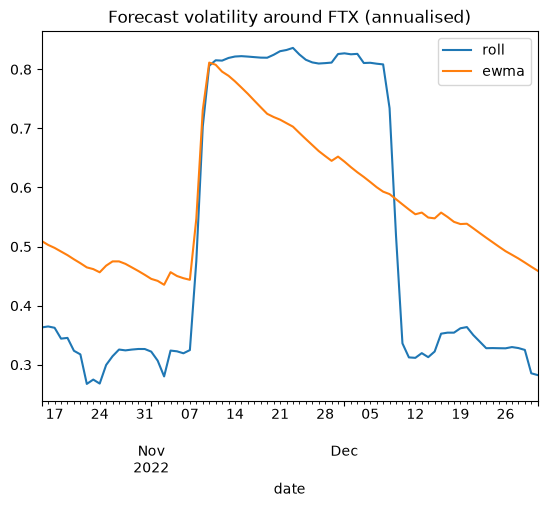

In [5]:
fc = pd.DataFrame({"roll": roll, "ewma": ew})
fc.to_csv("../data_clean/vol_forecasts.csv")
(np.sqrt(fc * 365)).loc["2022-10-15":"2022-12-31"].plot(title="Forecast volatility around FTX (annualised)")